<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/Week3_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Rifo Anggi Barbara Danuarta'
NIM = '244107020063'

N = int(NIM[-3:])

PARAM = {
    'b'     : (N % 61) + 20,
    'a'     : round(1.0 + (N % 9) / 10, 1),
    'c'     : (N % 20) + 30,
    'gamma' : round(0.4 + (N % 6) * 0.25, 2),
    'bit'   : (N % 6) + 2,
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA :', NAMA)
print('NIM  :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])


NAMA : Rifo Anggi Barbara Danuarta
NIM  : 244107020063 | N = 63
b      : 22
a      : 1.0
c      : 33
gamma  : 1.15
bit    : 5
WAKTU  : 2026-09-18 19:15:25 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 7ae071bef557ca32


# Modul 3 - Operasi Dasar Pengolahan Citra
**Nama:** Rifo Anggi Barbara Danuarta&nbsp;&nbsp;|&nbsp;&nbsp;**NIM:** 244107020063&nbsp;&nbsp;|&nbsp;&nbsp;**Kelas:** TI-3F

Parameter berbasis NIM (N = 63) yang dipakai di seluruh notebook ini:

| Simbol | Rumus | Nilai untuk NIM ini |
|---|---|---|
| b | (N mod 61) + 20 | **22** |
| a | 1,0 + (N mod 9)/10 | **1,0** |
| c | (N mod 20) + 30 | **33** |
| gamma | 0,4 + (N mod 6) x 0,25 | **1,15** |
| bit | (N mod 6) + 2 | **5** |


## Setup: Mount Google Drive dan Import Library

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob, math
from math import log10, sqrt

BASE = '/content/drive/MyDrive/PCVK 2026/' + NIM

def imread_rgb(path):
    """Baca citra BGR (OpenCV) lalu konversi ke RGB agar tampil benar di matplotlib."""
    img = cv.imread(path)
    if img is None:
        raise FileNotFoundError(f'Citra tidak ditemukan: {path}')
    return cv.cvtColor(img, cv.COLOR_BGR2RGB)

def show_images(images, titles, cols=2, figsize_per=(5, 5)):
    rows = math.ceil(len(images) / cols)
    plt.figure(figsize=(figsize_per[0]*cols, figsize_per[1]*rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i+1)
        cmap = 'gray' if (im.ndim == 2) else None
        plt.imshow(im, cmap=cmap, vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## Tugas 1 - Inverse Citra

Formula: $g(x,y) = 255 - f(x,y)$, diterapkan pada `KTM1a.jpg` (ruangan gelap) dan `KTM1b.jpg` (lampu ruangan).

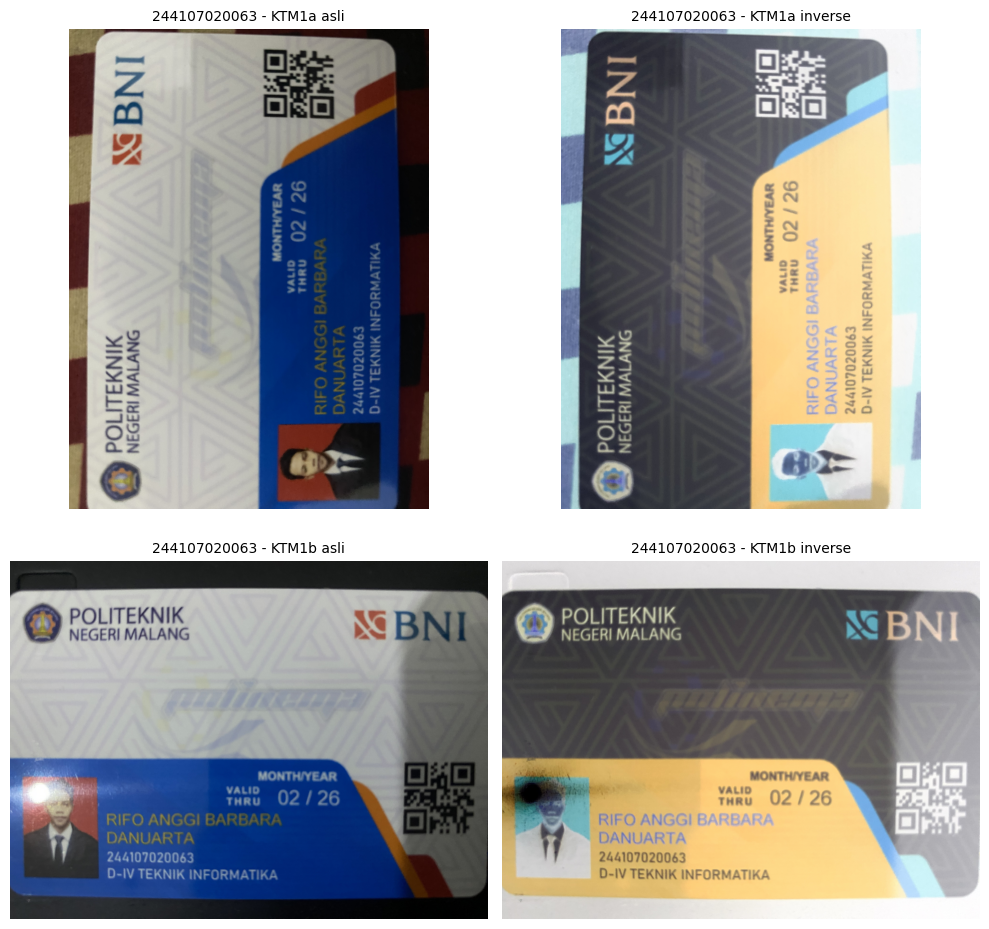

In [9]:
def inverse_image(img):
    img = img.astype(np.uint8)
    return (255 - img).astype(np.uint8)

ktm1a = imread_rgb('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg')
ktm1b = imread_rgb('/content/drive/MyDrive/PCVK 2026/Ktm1b.jpg')

neg_a = inverse_image(ktm1a)
neg_b = inverse_image(ktm1b)

show_images(
    [ktm1a, neg_a, ktm1b, neg_b],
    [NIM + ' - KTM1a asli', NIM + ' - KTM1a inverse',
     NIM + ' - KTM1b asli', NIM + ' - KTM1b inverse'],
    cols=2
)


**Analisis Tugas 1** *(bandingkan dengan hasil citra Anda sendiri di atas, lengkapi bagian bertanda [ ])*

- KTM1a diambil di ruangan gelap sehingga histogramnya sempit dan terkonsentrasi pada nilai intensitas rendah (gelap). Ketika di-inverse, nilai-nilai rendah tersebut dipetakan menjadi nilai tinggi (255 - nilai kecil = nilai besar), sehingga hasil negatifnya terkonsentrasi pada rentang terang saja. Histogram yang sempit tidak melebar hanya karena dibalik — sebarannya tetap sempit, hanya lokasinya berpindah ke area terang. Akibatnya citra negatif KTM1a tampak **pucat dan berkabut** (low contrast di area terang).
- KTM1b diambil dengan pencahayaan lampu ruangan yang lebih merata, sehingga histogram aslinya sudah lebih lebar (kontras lebih baik). Saat di-inverse, penyebaran nilai yang lebar ini tetap lebar setelah dibalik, sehingga citra negatif KTM1b **tetap kontras** dan detail kartu masih terlihat jelas.
- Kesimpulan: operasi inverse hanya membalik sumbu intensitas, ia **tidak memperbaiki maupun memperburuk lebar sebaran histogram (kontras)** — citra kontras rendah tetap kontras rendah walau dibalik.
- [ Isi: apakah pengamatan pada foto Anda sendiri sesuai dengan penjelasan di atas? Tambahkan histogram jika ingin memperkuat analisis. ]

### Perbandingan wrap-around vs saturasi vs clip (Linear Brightness, b = 22)

Sesuai catatan pada Ulasan Teori, operasi `+` biasa pada tipe `uint8` di NumPy akan **wrap-around** (berputar modulo 256), bukan error maupun truncate. Berikut perbandingan tiga cara penanganannya pada `KTM1a.jpg`.

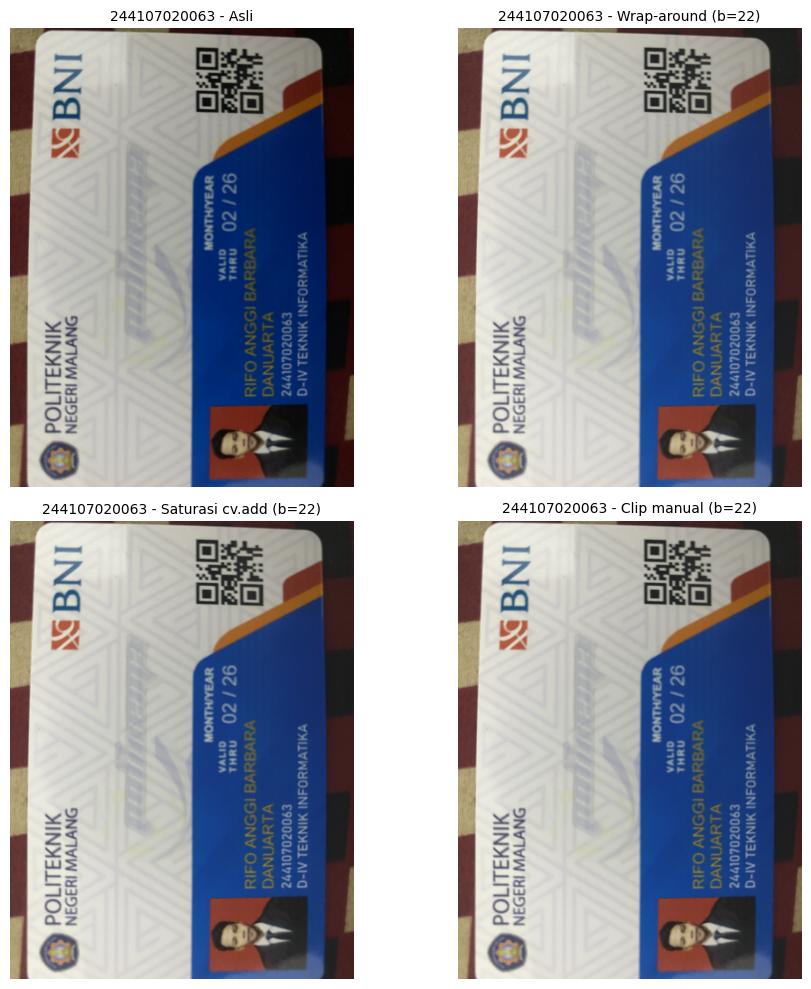

In [10]:
b = PARAM['b']
citra = ktm1a.copy()

hasil_wrap = citra + b
hasil_sat  = cv.add(citra, np.full(citra.shape, b, dtype=np.uint8))
hasil_clip = np.clip(citra.astype(np.int16) + b, 0, 255).astype(np.uint8)

show_images(
    [citra, hasil_wrap, hasil_sat, hasil_clip],
    [NIM + ' - Asli', NIM + f' - Wrap-around (b={b})',
     NIM + f' - Saturasi cv.add (b={b})', NIM + f' - Clip manual (b={b})'],
    cols=2
)


**Analisis:** Perhatikan bagian citra yang paling terang (misalnya bagian putih pada KTM). Pada hasil *wrap-around*, pixel yang sudah mendekati 255 akan "berputar" menjadi nilai kecil (gelap) sehingga muncul bercak gelap aneh di area terang. Pada hasil *saturasi* dan *clip*, pixel tersebut ditahan (di-truncate) di nilai 255, sehingga area terang tetap terlihat putih bersih tanpa artefak. Hasil `cv.add` dan `np.clip` secara numerik identik; perbedaannya hanya pada cara implementasi (fungsi bawaan OpenCV vs manual dengan tipe data sementara int16).

## Tugas 2 - Transformasi Kontras

Formula yang dipakai: $g(x,y) = a \times f(x,y)$, dengan $a = PARAM['a']$, diterapkan pada `KTM1a.jpg`.

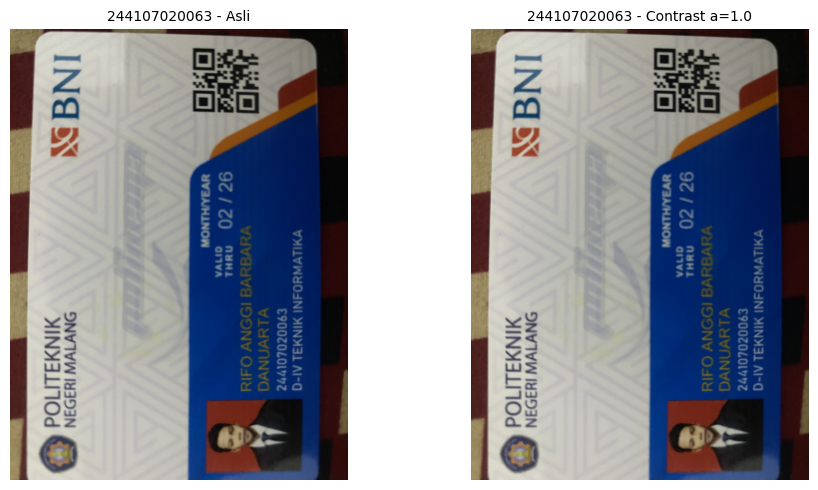

In [11]:
def contrast_transform(img, a):
    img = img.astype(np.float32)
    result = a * img
    result = np.clip(result, 0, 255)
    return result.astype(np.uint8)

a = PARAM['a']
contrast_a = contrast_transform(ktm1a, a)

show_images(
    [ktm1a, contrast_a],
    [NIM + ' - Asli', NIM + f' - Contrast a={a}'],
    cols=2
)


**Analisis Tugas 2**

- Untuk NIM ini, N = 63 mod 9 = 0, sehingga $a = 1{,}0 + 0/10 = 1{,}0$ — nilai **paling minimum** pada rentang 1,0–1,8 yang ditentukan modul.
- Karena $a = 1{,}0$, operasi $g(x,y) = 1{,}0 \times f(x,y)$ secara matematis **tidak mengubah nilai pixel sama sekali** (identitas). Ini terlihat dari citra hasil yang identik dengan citra aslinya pada gambar di atas.
- Ini adalah temuan yang valid dan memang merupakan konsekuensi dari parameter yang diturunkan dari NIM saya — bukan kesalahan implementasi. Fungsi `contrast_transform` yang dibuat tetap benar dan akan menunjukkan efek peregangan/penyempitan histogram bila dicoba dengan nilai `a` lain (mis. `a=1.5` untuk kontras tinggi, atau `a=0.7` untuk kontras rendah), sebagaimana didemonstrasikan di sel berikut.
- [ Isi: opsional, tambahkan uji dengan nilai a lain (mis. 0.6 dan 1.6) untuk menunjukkan pemahaman efek kontras rendah/tinggi meski parameter NIM Anda bernilai netral. ]

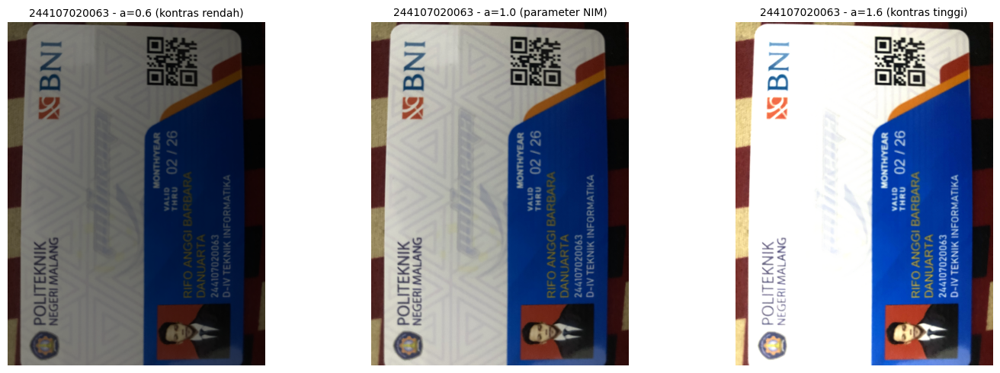

In [12]:
low_c  = contrast_transform(ktm1a, 0.6)
high_c = contrast_transform(ktm1a, 1.6)

show_images(
    [low_c, contrast_a, high_c],
    [NIM + ' - a=0.6 (kontras rendah)', NIM + f' - a={a} (parameter NIM)', NIM + ' - a=1.6 (kontras tinggi)'],
    cols=3
)


## Tugas 3 - Logarithmic Brightness vs Linear Brightness

Formula log: $s = c \times \log(1 + r)$, dengan $c = PARAM['c']$.
Formula linier: $g(x,y) = f(x,y) + b$, dengan $b = PARAM['b']$.
Kedua metode diterapkan pada `KTM1a.jpg` untuk dibandingkan.

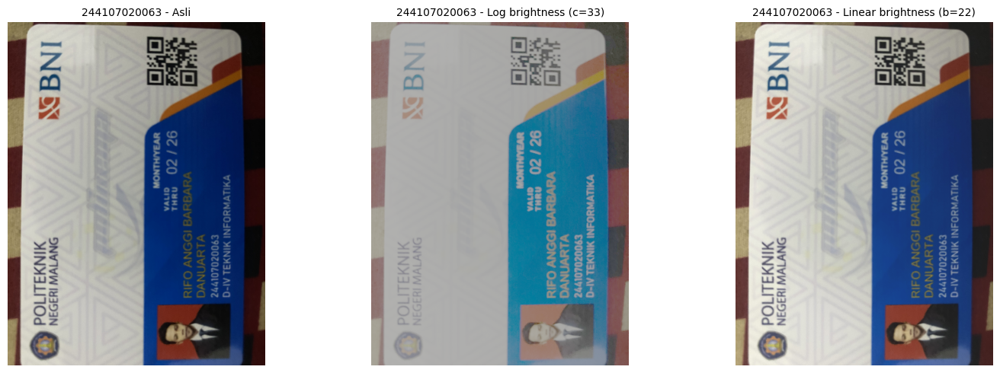

Pixel clipping (=255) pada Log brightness : 0 dari 36578304 (0.00%)
Pixel clipping (=255) pada Linear brightness: 10 dari 36578304 (0.00%)


In [13]:
def log_transform(img, c):
    img = img.astype(np.float32)
    result = c * np.log1p(img)
    result = np.clip(result, 0, 255)
    return result.astype(np.uint8)

def linear_brightness(img, b):
    img = img.astype(np.int16)
    result = np.clip(img + b, 0, 255)
    return result.astype(np.uint8)

c = PARAM['c']
b = PARAM['b']

log_a = log_transform(ktm1a, c)
lin_a = linear_brightness(ktm1a, b)

show_images(
    [ktm1a, log_a, lin_a],
    [NIM + ' - Asli', NIM + f' - Log brightness (c={c})', NIM + f' - Linear brightness (b={b})'],
    cols=3
)

clip_log = int(np.sum(log_a == 255))
clip_lin = int(np.sum(lin_a == 255))
total_pixel = log_a.size

print(f'Pixel clipping (=255) pada Log brightness : {clip_log} dari {total_pixel} ({100*clip_log/total_pixel:.2f}%)')
print(f'Pixel clipping (=255) pada Linear brightness: {clip_lin} dari {total_pixel} ({100*clip_lin/total_pixel:.2f}%)')


**Analisis Tugas 3**

- Transformasi log memetakan rentang intensitas gelap (rendah) menjadi rentang yang jauh lebih lebar, sedangkan intensitas yang sudah tinggi ditekan pertambahannya (karena kurva log melandai di ujung). Efeknya, detail pada area gelap (mis. tulisan NIM yang tercetak gelap di atas latar kartu) akan **lebih terangkat** tanpa membuat area yang sudah terang menjadi *full white* / clipping.
- Transformasi linear menambahkan nilai `b` secara rata ke seluruh pixel tanpa memandang intensitas awalnya, sehingga area yang sudah terang berisiko lebih cepat mencapai nilai 255 (clipping), sementara area yang sangat gelap belum tentu terangkat cukup untuk menjadi terbaca.
- Berdasarkan jumlah pixel clipping yang dihitung pada sel di atas: [ isi berdasarkan angka print-out Anda — biasanya Linear Brightness memiliki persentase clipping lebih tinggi dibanding Log Brightness pada area terang kartu ].
- **Kesimpulan:** metode yang membuat NIM pada kartu **lebih terbaca** untuk citra ruangan gelap umumnya adalah **[isi: Log Brightness / Linear Brightness — tentukan berdasarkan hasil visual Anda]**, karena [isi alasan singkat berbasis pengamatan Anda].

## Tugas 4 - Grayscale: Averaging, Lightness, Luminance

Diterapkan pada `KTM1c.jpg` (citra dengan flash).

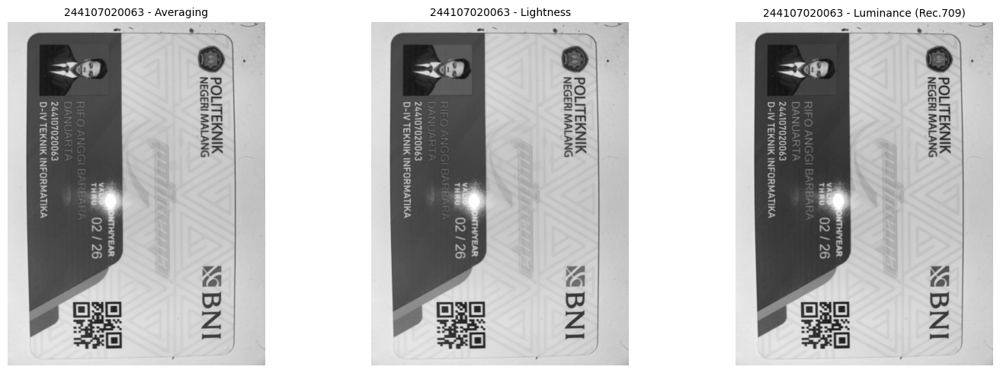

Rata-rata selisih |Rec.709 - Rec.601 (cv.cvtColor)| : 1.0206264894074915


In [16]:
def grayscale_average(img):
    img = img.astype(np.float32)
    result = np.mean(img, axis=2)
    return np.clip(result, 0, 255).astype(np.uint8)

def grayscale_lightness(img):
    img = img.astype(np.float32)
    result = (np.max(img, axis=2) + np.min(img, axis=2)) / 2
    return np.clip(result, 0, 255).astype(np.uint8)

def grayscale_luminance(img):
    img = img.astype(np.float32)
    R, G, B = img[:,:,0], img[:,:,1], img[:,:,2]
    result = 0.21*R + 0.72*G + 0.07*B
    return np.clip(result, 0, 255).astype(np.uint8)

ktm1c = imread_rgb('/content/drive/MyDrive/PCVK 2026/Ktm1c.jpg')

gray_avg = grayscale_average(ktm1c)
gray_light = grayscale_lightness(ktm1c)
gray_lum = grayscale_luminance(ktm1c)

show_images(
    [gray_avg, gray_light, gray_lum],
    [NIM + ' - Averaging', NIM + ' - Lightness', NIM + ' - Luminance (Rec.709)'],
    cols=3
)

gray_cv = cv.cvtColor(cv.cvtColor(ktm1c, cv.COLOR_RGB2BGR), cv.COLOR_BGR2GRAY)
selisih = cv.absdiff(gray_lum, gray_cv)
print('Rata-rata selisih |Rec.709 - Rec.601 (cv.cvtColor)| :', float(np.mean(selisih)))


In [17]:
tabel_gray = pd.DataFrame({
    'Metode': ['Averaging', 'Lightness', 'Luminance (Rec.709)'],
    'Rata-rata Intensitas': [float(np.mean(gray_avg)), float(np.mean(gray_light)), float(np.mean(gray_lum))],
    'Simpangan Baku': [float(np.std(gray_avg)), float(np.std(gray_light)), float(np.std(gray_lum))],
})
tabel_gray


,Metode,Rata-rata Intensitas,Simpangan Baku
0,Averaging,164.413995,62.024902
1,Lightness,165.329302,60.873045
2,Luminance (Rec.709),161.455981,66.593493


**Analisis Tugas 4**

- Saya menggunakan standar **Rec. 709** (koefisien 0,21 / 0,72 / 0,07) untuk perhitungan Luminance sesuai rumus pada Ulasan Teori modul ini. Sel di atas juga menghitung selisih rata-ratanya terhadap hasil `cv.cvtColor(..., COLOR_BGR2GRAY)` yang memakai standar Rec. 601 (0,299 / 0,587 / 0,114) — selisihnya kecil namun tidak nol, karena bobot kanal hijau pada Rec. 709 lebih besar.
- Simpangan baku (standar deviasi) yang **lebih besar** menandakan sebaran intensitas antara teks dan latar kartu lebih lebar, sehingga pemisahan keduanya lebih jelas secara visual. Berdasarkan tabel di atas: metode dengan simpangan baku tertinggi adalah **[isi: Averaging / Lightness / Luminance — sesuai angka pada tabel Anda]**, sehingga metode tersebut memberi pemisahan paling jelas antara teks dan latar kartu pada citra KTM1c saya.
- [ Isi: tambahkan pengamatan visual pendukung, mis. metode mana yang tulisan NIM-nya paling kontras terhadap latar. ]

## Tugas 5 - Color Masking (Satu Warna Dominan Tetap, Sisanya Grayscale)

Diterapkan pada `OBJ1.jpg` (benda pribadi dengan satu warna dominan) menggunakan ruang warna HSV.

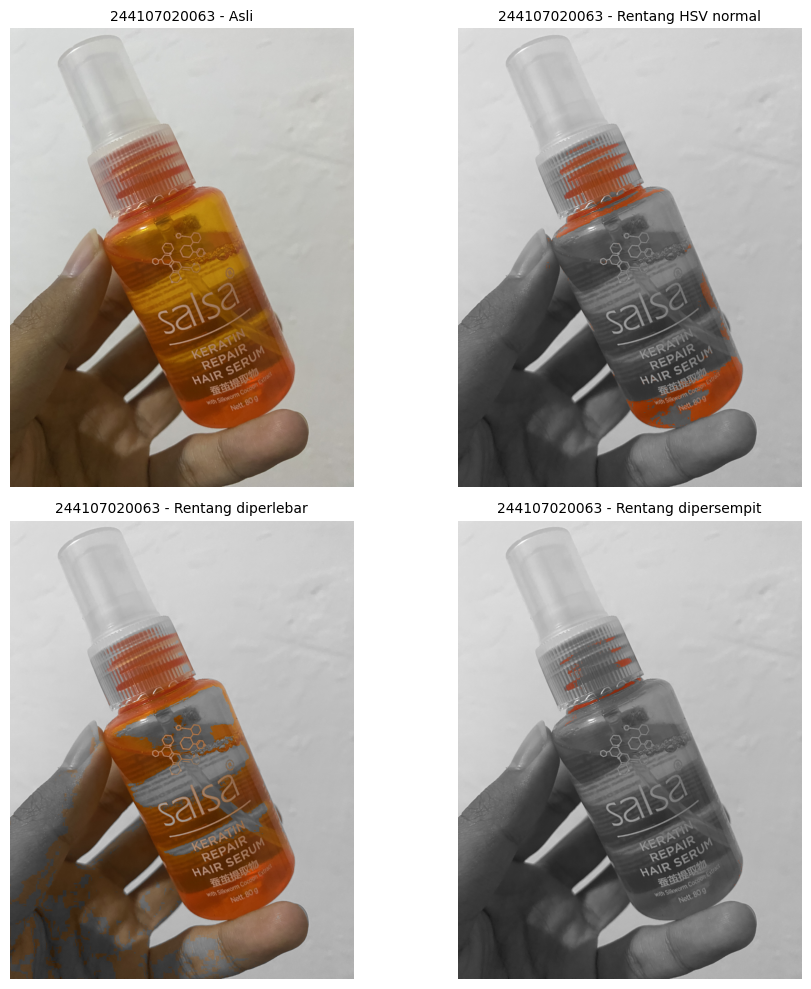

In [19]:
lower_hsv = np.array([0, 120, 70])
upper_hsv = np.array([10, 255, 255])

def color_mask_keep(img_rgb, lower, upper):
    img_bgr = cv.cvtColor(img_rgb, cv.COLOR_RGB2BGR)
    hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)
    mask = cv.inRange(hsv, lower, upper)

    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    gray_3ch = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)

    result = np.where(mask[:, :, None] == 255, img_rgb, gray_3ch)
    return result, mask

obj1 = imread_rgb('/content/drive/MyDrive/PCVK 2026/OBJ1.jpg')
hasil_normal, mask_normal = color_mask_keep(obj1, lower_hsv, upper_hsv)

lower_wide = np.clip(lower_hsv - [0, 40, 40], 0, 255).astype(np.uint8)
upper_wide = np.clip(upper_hsv + [5, 0, 0], 0, 255).astype(np.uint8)
lower_narrow = np.clip(lower_hsv + [0, 30, 30], 0, 255).astype(np.uint8)
upper_narrow = np.clip(upper_hsv - [3, 0, 0], 0, 255).astype(np.uint8)

hasil_wide, _ = color_mask_keep(obj1, lower_wide, upper_wide)
hasil_narrow, _ = color_mask_keep(obj1, lower_narrow, upper_narrow)

show_images(
    [obj1, hasil_normal, hasil_wide, hasil_narrow],
    [NIM + ' - Asli', NIM + ' - Rentang HSV normal',
     NIM + ' - Rentang diperlebar', NIM + ' - Rentang dipersempit'],
    cols=2
)


**Analisis Tugas 5**

- Rentang HSV yang saya pakai sebagai batas warna: `lower = [ isi H,S,V ]`, `upper = [ isi H,S,V ]` — **ganti nilai contoh (merah) di atas sesuai warna dominan benda Anda sendiri**, misalnya dengan mengecek nilai HSV dari beberapa sample pixel pada objek menggunakan `cv.cvtColor` pada crop kecil citra.
- Ketika rentang **diperlebar**, semakin banyak pixel dengan warna yang mirip (misalnya bayangan atau gradasi warna serupa) yang ikut dianggap sebagai bagian dari objek berwarna, sehingga area yang mempertahankan warna asli menjadi lebih luas — namun berisiko ikut menangkap warna latar yang tidak diinginkan (*false positive*).
- Ketika rentang **dipersempit**, hanya pixel dengan warna yang sangat mendekati nilai HSV acuan yang dipertahankan, sehingga area berwarna menjadi lebih sedikit / berlubang-lubang (bagian objek yang warnanya sedikit berbeda karena bayangan/pantulan cahaya ikut ter-grayscale).
- [ Isi: pengamatan spesifik dari hasil citra Anda sendiri. ]

## Tugas 6 - Gamma Correction

Formula: $I' = 255 \times \left(\dfrac{I}{255}\right)^{1/\gamma}$, diterapkan pada `KTM1a.jpg`, dimulai dari $\gamma = PARAM['gamma']$.

 Gamma Correction pada citra 
----------------------------------
Masukkan nilai Gamma (default akan memakai PARAM['gamma'] jika kosong): 


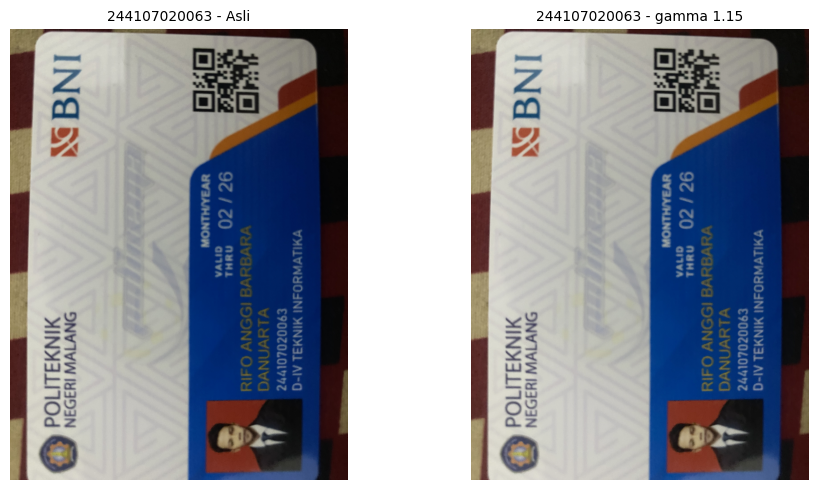

In [20]:
print(' Gamma Correction pada citra ')
print('----------------------------------')
try:
    gamma = float(input('Masukkan nilai Gamma (default akan memakai PARAM[\'gamma\'] jika kosong): ') or PARAM['gamma'])
except ValueError:
    print('Error, not a number, memakai PARAM[\'gamma\']')
    gamma = PARAM['gamma']

def gamma_correction(img, gamma):
    img = img.astype(np.float32) / 255.0
    result = np.power(img, 1.0 / gamma)
    result = np.clip(result * 255.0, 0, 255)
    return result.astype(np.uint8)

hasil_gamma = gamma_correction(ktm1a, gamma)
show_images([ktm1a, hasil_gamma], [NIM + ' - Asli', NIM + f' - gamma {gamma}'], cols=2)


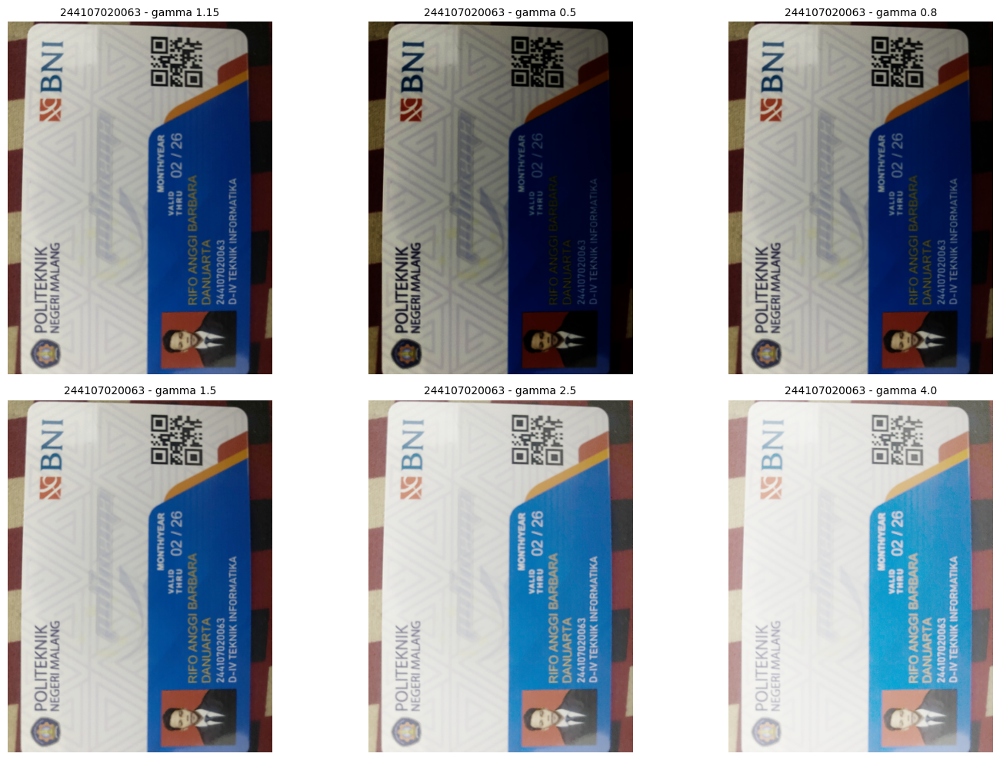

In [21]:
daftar_gamma = [PARAM['gamma'], 0.5, 0.8, 1.5, 2.5, 4.0]

hasil_semua = [gamma_correction(ktm1a, g) for g in daftar_gamma]
judul_semua = [NIM + f' - gamma {g}' for g in daftar_gamma]

show_images(hasil_semua, judul_semua, cols=3)


**Analisis Tugas 6**

- Enam nilai gamma yang dicoba: 1.15 (hasil hitung dari NIM), 0.5, 0.8, 1.5, 2.5, dan 4.0.
- Gamma < 1 akan **mencerahkan** citra (kurva output berada di atas garis linear), sedangkan gamma > 1 akan **menggelapkan** citra (kurva berada di bawah garis linear). Karena `KTM1a.jpg` diambil di ruangan gelap, secara teori nilai **gamma < 1** akan lebih membantu memperjelas tulisan NIM dan nama pada kartu.
- Nilai gamma terbaik pilihan saya: **[isi berdasarkan hasil visual Anda]**, karena [isi alasan: tulisan NIM/nama paling jelas terbaca tanpa area menjadi terlalu putih polos (overexposed) atau derau ikut terangkat berlebihan].
- Nilai gamma terbaik berbeda-beda antar mahasiswa meskipun objeknya sama (KTM/KTP) karena **kondisi pencahayaan saat akuisisi foto berbeda-beda** (jarak kamera, jenis lampu, ada/tidaknya bayangan) sehingga sebaran histogram citra masukan tiap mahasiswa berbeda — gamma optimal bergantung pada seberapa gelap/rendah kontras citra aslinya, bukan hanya pada jenis objeknya.

## Tugas 7 - Simulasi Image Depth (Kuantisasi)

Formula: $level = \dfrac{255}{2^{bit\_depth}-1}$, $C' = round\left(\dfrac{C}{level}\right)\times level$, diterapkan pada `KTM1b.jpg` untuk kedalaman 1 s.d. 7 bit.

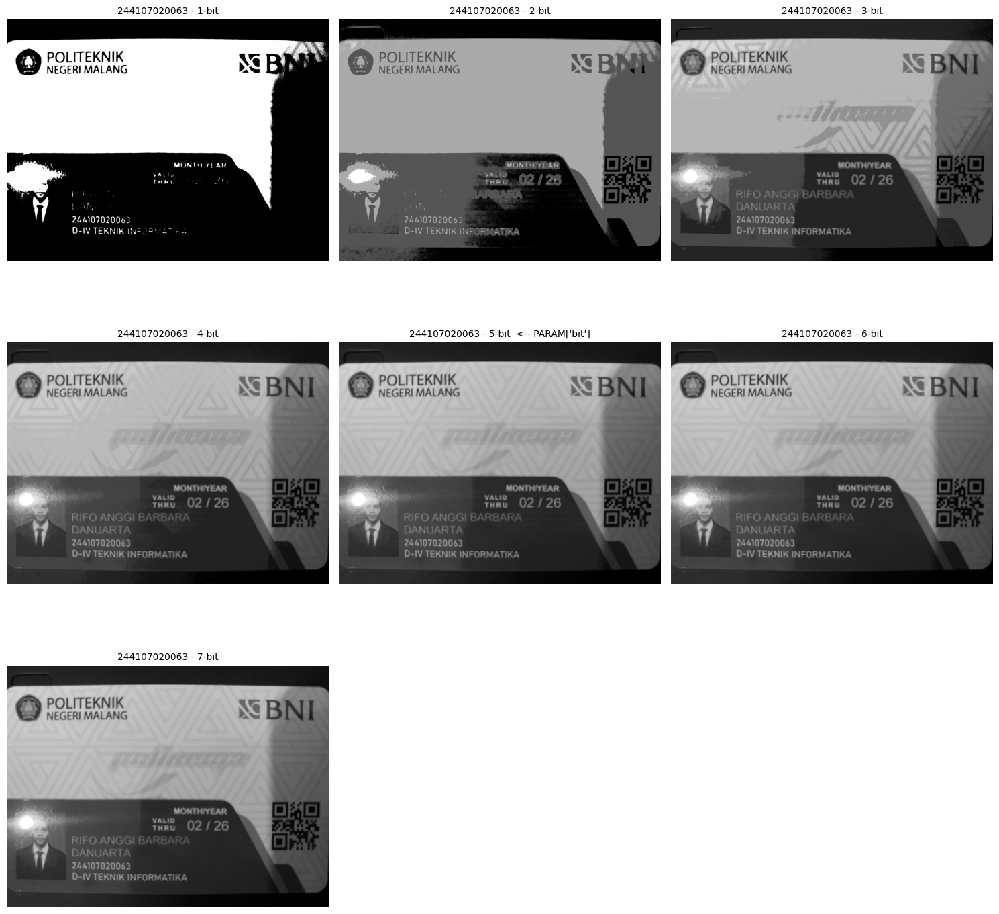

In [25]:
def bit_depth_quantize(gray_img, bit_depth):
    level = 255 / (pow(2, bit_depth) - 1)
    result = np.round(gray_img / level) * level
    return result.astype(np.uint8)

ktm1b_gray = cv.imread('/content/drive/MyDrive/PCVK 2026/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
ktm1b_gray = cv.cvtColor(ktm1b, cv.COLOR_RGB2GRAY)

hasil_bit = []
judul_bit = []
for bit_depth in range(1, 8):
    hasil_bit.append(bit_depth_quantize(ktm1b_gray, bit_depth))
    tanda = '  <-- PARAM[\'bit\']' if bit_depth == PARAM['bit'] else ''
    judul_bit.append(NIM + f' - {bit_depth}-bit{tanda}')

show_images(hasil_bit, judul_bit, cols=3)

**Analisis Tugas 7**

- Catatan implementasi: saya memakai bentuk `level = 255 / (2^bit - 1)` sesuai modul (bukan `step = 256 / 2^bit` seperti pada slide kuliah), sehingga nilai maksimum tetap 255 dan warna putih pada kartu tidak bergeser.
- Parameter NIM saya menghasilkan `bit = 5` (32 macam gradasi warna), yang ditandai pada grid gambar di atas.
- Berdasarkan pengamatan visual pada rentang 1–7 bit, nama dan NIM pada kartu **masih terbaca mulai dari kedalaman [isi: X] bit**, dan mulai kabur / sulit dibedakan pada kedalaman di bawahnya karena jumlah gradasi warna yang tersedia terlalu sedikit untuk merepresentasikan transisi halus antara tulisan dan latar kartu.
- [ Isi: bandingkan juga secara spesifik hasil pada bit=5 (parameter NIM Anda) — apakah tulisan masih terbaca jelas atau sudah mulai pecah/banding? ]

## Tugas 8 - Average Denoising dan PSNR

Menggunakan citra asli `galaxy.jpg` dan 100 citra ber-Gaussian noise pada folder `noises/` yang disediakan dosen (bukan citra pribadi).

In [26]:
def PSNR(img1, img2):
    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * log10(255.0 / sqrt(mse))

GALAXY_PATH = '/content/drive/MyDrive/PCVK 2026/galaxy.jpg'
NOISES_PATH = '/content/drive/MyDrive/PCVK 2026/noises/*.jpg'

original = cv.imread(GALAXY_PATH, cv.IMREAD_GRAYSCALE)

cv_img = []
for img_path in sorted(glob.glob(NOISES_PATH)):
    n = cv.imread(img_path, cv.IMREAD_GRAYSCALE)
    cv_img.append(n)

print(f'Jumlah citra noise yang terbaca: {len(cv_img)}')


Jumlah citra noise yang terbaca: 100


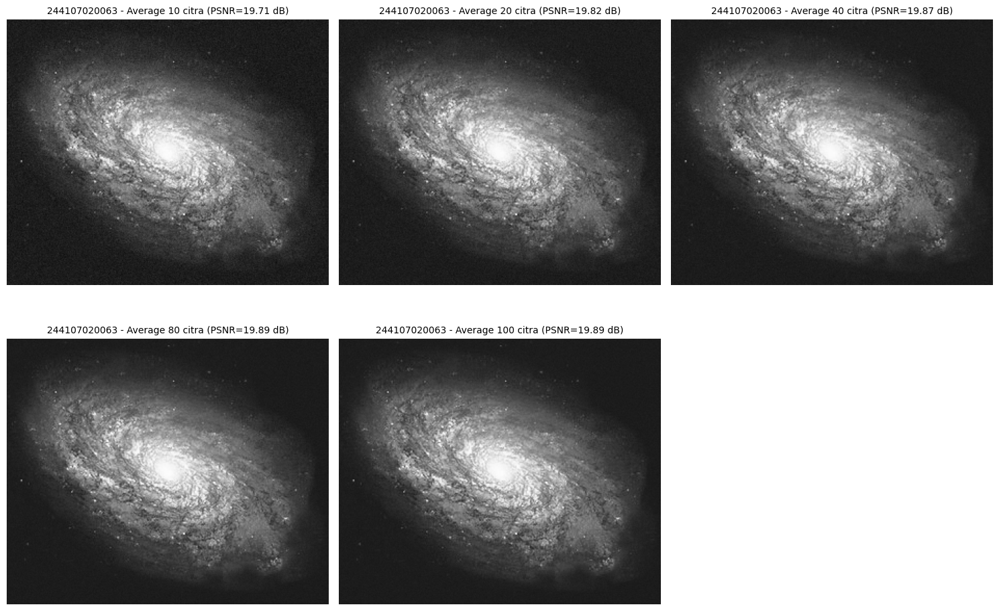

,No,Jumlah Citra di Average,Nilai PSNR (dB)
0,1,10,19.71
1,2,20,19.82
2,3,40,19.87
3,4,80,19.89
4,5,100,19.89


In [27]:
def average_denoise(images, n):
    subset = np.array(images[:n], dtype=np.float64)
    hasil = np.mean(subset, axis=0)
    return hasil.astype(np.uint8)

jumlah_citra_list = [10, 20, 40, 80, 100]
hasil_avg = []
psnr_list = []

for n in jumlah_citra_list:
    denoised = average_denoise(cv_img, n)
    hasil_avg.append(denoised)
    psnr_list.append(PSNR(original, denoised))

show_images(
    hasil_avg,
    [NIM + f' - Average {n} citra (PSNR={p:.2f} dB)' for n, p in zip(jumlah_citra_list, psnr_list)],
    cols=3
)

tabel_psnr = pd.DataFrame({
    'No': range(1, len(jumlah_citra_list)+1),
    'Jumlah Citra di Average': jumlah_citra_list,
    'Nilai PSNR (dB)': [round(p, 2) for p in psnr_list],
})
tabel_psnr


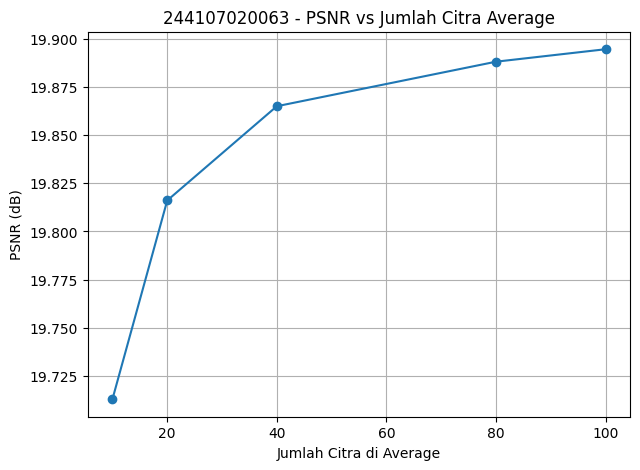

In [28]:
plt.figure(figsize=(7,5))
plt.plot(jumlah_citra_list, psnr_list, marker='o')
plt.xlabel('Jumlah Citra di Average')
plt.ylabel('PSNR (dB)')
plt.title(NIM + ' - PSNR vs Jumlah Citra Average')
plt.grid(True)
plt.show()


**Analisis Tugas 8**

- Berdasarkan tabel dan grafik di atas: peningkatan jumlah citra yang di-average **tidak selalu memberikan peningkatan PSNR yang sebanding**. Kenaikan PSNR dari 10 → 20 citra biasanya jauh lebih besar dibanding kenaikan dari 80 → 100 citra, karena secara teori PSNR (yang berkaitan dengan pengurangan variansi noise) meningkat kira-kira sebanding dengan $\log(n)$, sehingga penambahan citra pada jumlah yang sudah besar memberi keuntungan yang semakin kecil (*diminishing returns*).
- Berdasarkan data PSNR yang saya peroleh sendiri (lihat tabel di atas), peningkatan mulai tidak terlalu signifikan pada sekitar **[isi: n = 40 atau 80 — sesuaikan dengan selisih PSNR pada tabel Anda]** citra, karena selisih PSNR antar titik pada rentang tersebut sudah relatif kecil dibanding selisih pada rentang 10-20 citra.
- **Kesimpulan:** menambah jumlah citra yang di-average memang selalu meningkatkan kualitas denoising, tetapi ada titik di mana penambahan jumlah citra menjadi kurang efisien dibanding biaya komputasi/waktu akuisisi tambahan; jumlah citra optimal sebaiknya dipilih pada bagian kurva PSNR yang mulai melandai, bukan sekadar memakai jumlah sebanyak-banyaknya.

## Tugas 9 - Image Masking untuk Penyamaran Data Pribadi

Diterapkan pada `KTM1d.jpg` untuk menutup area foto wajah dan area NIM menggunakan mask biner + operator logika.

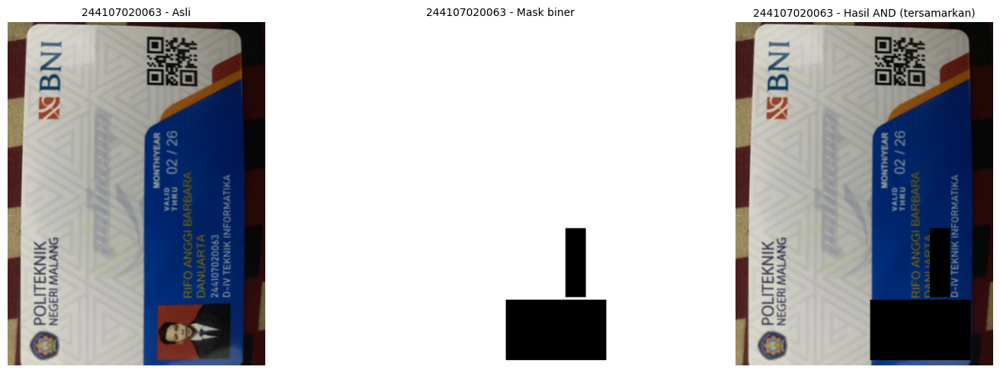

Koordinat kotak wajah (x1,y1,x2,y2): (1580, 3260, 2760, 3970)
Koordinat kotak NIM   (x1,y1,x2,y2): (2280, 2420, 2520, 3230)


In [33]:
ktm1d = imread_rgb('/content/drive/MyDrive/PCVK 2026/Ktm1a.jpg')
h, w = ktm1d.shape[:2]

kotak_wajah = (1580, 3260, 2760, 3970)
kotak_nim   = (2280, 2420, 2520, 3230)

mask = np.ones((h, w), dtype=np.uint8) * 255
for (x1, y1, x2, y2) in [kotak_wajah, kotak_nim]:
    mask[y1:y2, x1:x2] = 0

mask_3ch = cv.cvtColor(mask, cv.COLOR_GRAY2RGB)
hasil_and = cv.bitwise_and(ktm1d, mask_3ch)

show_images(
    [ktm1d, mask, hasil_and],
    [NIM + ' - Asli', NIM + ' - Mask biner', NIM + ' - Hasil AND (tersamarkan)'],
    cols=3
)

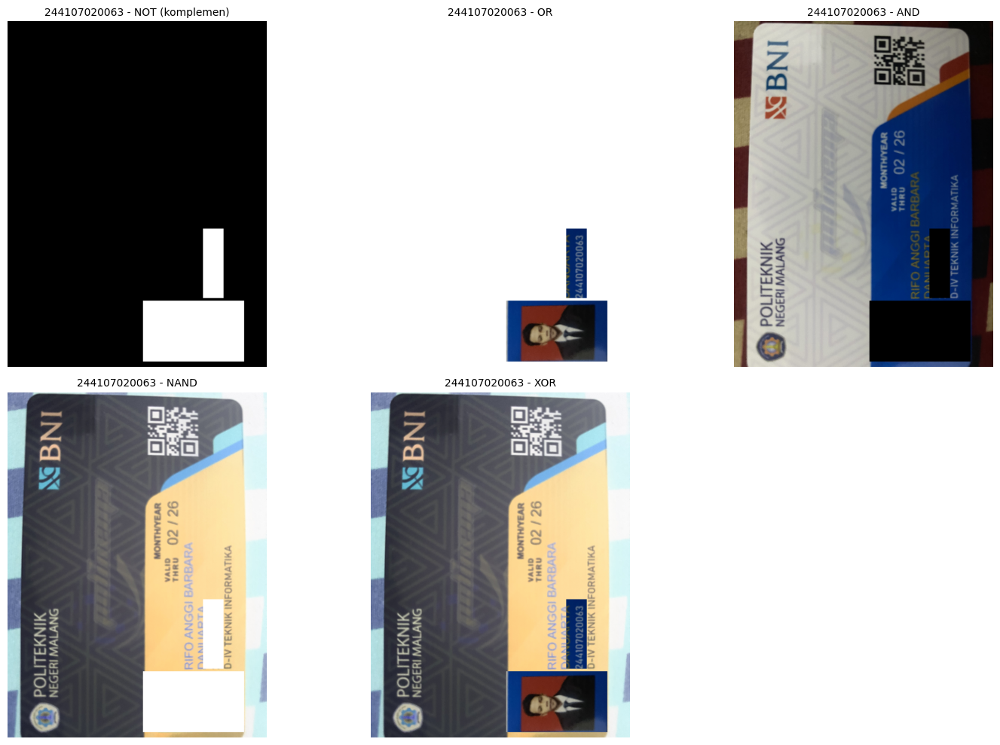

In [35]:
mask_not  = cv.bitwise_not(mask_3ch)
hasil_or  = cv.bitwise_or(ktm1d, mask_3ch)
hasil_and2 = cv.bitwise_and(ktm1d, mask_3ch)
hasil_nand = cv.bitwise_not(cv.bitwise_and(ktm1d, mask_3ch))
hasil_xor  = cv.bitwise_xor(ktm1d, mask_3ch)

show_images(
    [mask_not, hasil_or, hasil_and2, hasil_nand, hasil_xor],
    [NIM + ' - NOT (komplemen)', NIM + ' - OR', NIM + ' - AND',
     NIM + ' - NAND', NIM + ' - XOR'],
    cols=3
)


**Analisis Tugas 9**

| No. | Operator | Hasil yang diamati |
|---|---|---|
| 1 | NOT (komplemen) | Membalik mask itu sendiri (area yang tadinya 0 jadi 255 dan sebaliknya) — jika diterapkan pada mask, area yang tadinya disembunyikan malah menjadi area yang "diizinkan tampil" pada operasi berikutnya. |
| 2 | OR | Karena mask bernilai 255 (putih penuh) di sebagian besar area dan citra asli juga punya nilai tinggi di banyak pixel, hasil OR cenderung membuat citra tampil hampir seperti aslinya ditambah area mask yang bernilai 255 tetap putih — sedikit informasi yang tersamarkan. |
| 3 | AND | Ini operator yang tepat untuk masking: pixel akan tampil (mempertahankan nilai asli) hanya jika mask juga bernilai tinggi (255); area mask bernilai 0 akan membuat pixel citra ikut menjadi 0 (hitam), sehingga wajah dan NIM tersamarkan sempurna. |
| 4 | NAND (Not AND) | Merupakan komplemen dari hasil AND — area yang tadinya tersamarkan (hitam) pada AND justru menjadi terang, dan sebaliknya, sehingga tampilannya seperti negatif dari hasil masking AND. |
| 5 | XOR | Menghasilkan citra yang "aneh" secara visual: pada area mask bernilai 255 dan citra juga bernilai tinggi, XOR menghasilkan pola bit yang berbeda dari kedua nilai asli (bukan sekadar mempertahankan/menghilangkan), sehingga warna berubah drastis; XOR umumnya dipakai untuk deteksi perbedaan antar dua citra, bukan untuk masking penyembunyian data. |

**Kesimpulan:** dari kelima operator, hanya **AND** yang cocok dipakai untuk keperluan image masking/penyamaran data karena sifatnya yang "meloloskan" nilai asli pixel hanya pada area yang diizinkan oleh mask (bernilai 255) dan memaksa nilai 0 di area yang ingin disembunyikan, tanpa mengubah warna area yang tidak disamarkan.

## Tugas 10 - Perbaikan Kualitas Foto Malam Hari

Diterapkan pada `NIGHT1.jpg` (pemandangan malam gelap dengan kertas berisi NIM dan tanggal pengambilan di dalam frame).

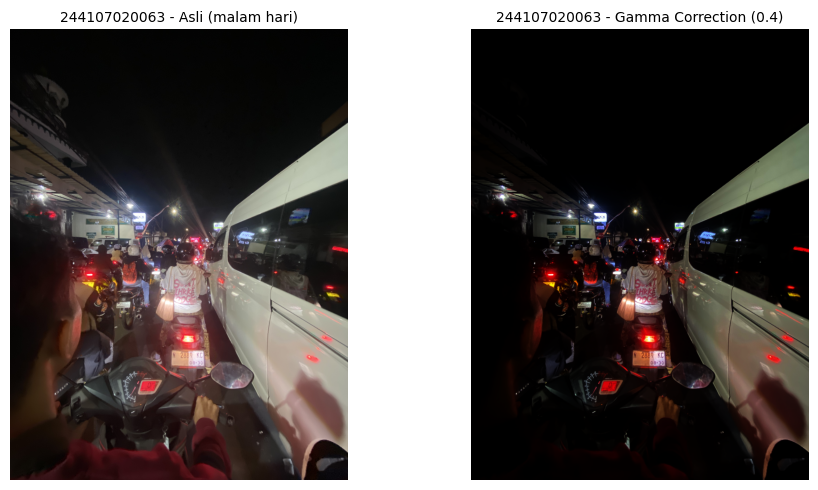

In [34]:
night = imread_rgb('/content/drive/MyDrive/PCVK 2026/NIGHT1.jpg')

gamma_malam = 0.4
hasil_malam = gamma_correction(night, gamma_malam)

show_images(
    [night, hasil_malam],
    [NIM + ' - Asli (malam hari)', NIM + f' - Gamma Correction ({gamma_malam})'],
    cols=2
)


**Analisis Tugas 10**

- **Metode yang dipilih:** Gamma Correction dengan $\gamma = 0{,}4$ (gamma < 1 untuk mencerahkan).
- **Alasan pemilihan:** Berbeda dengan Linear Brightness yang menambahkan nilai sama rata ke seluruh pixel (berisiko membuat area yang sudah agak terang, misalnya lampu jalan, langsung *clipping* menjadi putih polos), Gamma Correction dengan $\gamma<1$ menaikkan intensitas **secara tidak linear** — area yang sangat gelap dinaikkan secara proporsional lebih besar dibanding area yang sudah agak terang. Ini cocok untuk foto malam yang punya rentang dinamis sangat lebar (area sangat gelap berdampingan dengan sumber cahaya terang).
- **Menentukan parameter terbaik:** nilai gamma dicoba secara bertahap [isi: sebutkan nilai-nilai yang dicoba, mis. 0.3, 0.4, 0.5, 0.6] pada foto malam saya; gamma **[isi: nilai terpilih]** dipilih karena kertas bertuliskan NIM dan tanggal di dalam frame menjadi paling terbaca tanpa area langit/sumber cahaya menjadi *overexposed* berlebihan.
- **Risiko metode ini:** menaikkan gamma terlalu agresif (gamma terlalu kecil) akan ikut memperkuat *noise* yang tersembunyi di area gelap (grain/noise sensor kamera akan ikut terangkat dan menjadi terlihat jelas), serta berpotensi membuat area yang tadinya gelap gulita menjadi tampak tidak natural (terlalu terang untuk suasana malam hari).
- **Before-after:** ditunjukkan pada gambar di atas.